# Exploratory Data Analysis

In this notebook, we will investigate the data that will be used for this project through the following steps:
- Setup our data
- Downlaod PlantDoc and PlantVillage
- Perform Exploratory Data Analysis


**Note:**

This notebook must be executed in your local machine while using the `jute-disease-detection (3.11.14)(Python 3.11.14)` kernel.

## 1. Environment Setup

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys
from pathlib import Path

project_root = Path("../../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

2026-03-17 00:36:26,720 - autoreload - ERROR - Failed to read module file 'C:\Users\umali\AppData\Roaming\uv\python\cpython-3.11.14-windows-x86_64-none\Lib\re\_casefix.py' for module 're._casefix': UnicodeDecodeError
Traceback (most recent call last):
  File "c:\Users\umali\GithubProjects\jute-disease-detection\.venv\Lib\site-packages\IPython\core\extensions.py", line 62, in load_extension
    return self._load_extension(module_str)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\umali\GithubProjects\jute-disease-detection\.venv\Lib\site-packages\IPython\core\extensions.py", line 77, in _load_extension
    mod = import_module(module_str)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\umali\AppData\Roaming\uv\python\cpython-3.11.14-windows-x86_64-none\Lib\importlib\__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>

In [ ]:
import sys
from pathlib import Path

import matplotlib as plt
import seaborn as sns
from torchvision.datasets import ImageFolder

sys.path.append("../dev")

from EDA import EDA

from jute_disease.utils.constants import (
    BY_CLASS_DIR,
    DEFAULT_SEED,
    PLANTDOC_DIR,
    PLANTVILLAGE_DIR,
)
from jute_disease.utils.logger import get_logger
from src.jute_disease.utils.seed import seed_everything

In [ ]:
logger = get_logger(__name__)
seed_everything(DEFAULT_SEED)

plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

Seed set to 42


2026-03-17 00:36:44,496 - src.jute_disease.utils.seed - INFO - Random seed set to: 42


## 2. Prepare Datasets

Steps
1. Download <https://drive.google.com/drive/folders/1WoQ-Xzy0Prl9lInHW5JpGX4tpE9YDUua?usp=sharing>.
2. Setup your data directories by running the 
3. Update `DATA_ZIP_PATH` below to the path where you stored the file. If you uploaded it to the root of _My Drive_, you can set it to **"/content/drive/MyDrive/data.zip"**.

**STEP 1**: Setup the data directory by running following code block:

In [ ]:
from jute_disease.data.utils import initialize_data

initialize_data()

**STEP 2**: Download <https://drive.google.com/drive/folders/1WoQ-Xzy0Prl9lInHW5JpGX4tpE9YDUua?usp=sharing>.

**STEP 3**: Extract the `data.zip` then select the following folders then move them to the `by_class` folder:
- Cercospora Leaf Spot
- Dieback
- General Damage
- Healthy
- Mosaic
- Stem Rot


At this point, we have downloaded and prepared three datasets:
1. **PlantVillage**: a general dataset of diseased leaf images 
2. **PlantDoc**: a dataset of in-the-wild diseased leaf images  
3. Our curated Jute leaf disease and pest dataset compiled from different sources located in the `by_class` folder

We will be using PlantVillage and PlantDoc for multistage transfer learning and our curated dataset for fine-tuning. Our end goal is to train a model that performs excellently on our curated Jute leaf disease and pest dataset.

In [ ]:
jute_dataset = ImageFolder(root=BY_CLASS_DIR)
logger.info(f"Jute Dataset ({BY_CLASS_DIR}):")
logger.info(f"  - Total Images: {len(jute_dataset)}")
logger.info(f"  - Classes: {len(jute_dataset.classes)}")

plant_village_dir = PLANTVILLAGE_DIR
if plant_village_dir.exists():
    pv_dataset = ImageFolder(root=plant_village_dir)
    logger.info(f"\nPlantVillage Dataset ({plant_village_dir}):")
    logger.info(f"  - Total Images: {len(pv_dataset)}")
    logger.info(f"  - Classes: {len(pv_dataset.classes)}")
else:
    logger.warning("\nPlantVillage dataset not found! Check download step.")

2026-03-17 00:38:32,166 - __main__ - INFO - Jute Dataset (C:\Users\umali\GithubProjects\jute-disease-detection\data\by_class):
2026-03-17 00:38:32,166 - __main__ - INFO -   - Total Images: 2382
2026-03-17 00:38:32,166 - __main__ - INFO -   - Classes: 6
2026-03-17 00:38:33,489 - __main__ - INFO - 
PlantVillage Dataset (C:\Users\umali\GithubProjects\jute-disease-detection\data\external\plantvillage):
2026-03-17 00:38:33,489 - __main__ - INFO -   - Total Images: 54305
2026-03-17 00:38:33,489 - __main__ - INFO -   - Classes: 38


# Exploratory Data Analysis


### Class Distribution
To begin the EDA, we first have to understand the class distribution of the datasets we will be using for this project. There are three key sources for these data:  
- data.zip
- PlantVillage
- PlantDoc

The data.zip contains a collection of jute disease images that was gathered from varying open-source data repositories, specifically:
- Jute Disease Image Dataset from Harvard Dataverse: 
- Jute Disease Detection from Kaggle: 
- Jute Plant Leaves from Mendley

Among these open data repositories contained numerous classifications of diseases. We narrowed down the classes to be used into six, namely:
- Cercospora Leaf Spot
- Dieback
- General Damage
- Healthy
- Mosaic
- Stem Rot

The files were manually moved to the respective `/data/by_class` folders which will be used for the ML training. 

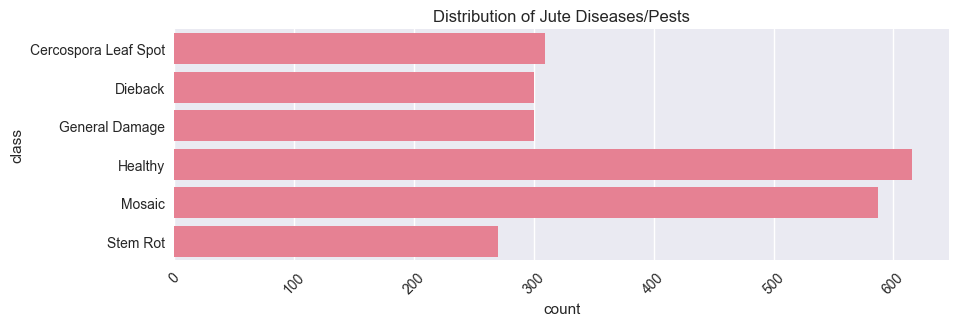

In [ ]:
EDA.get_class_distribution(BY_CLASS_DIR)

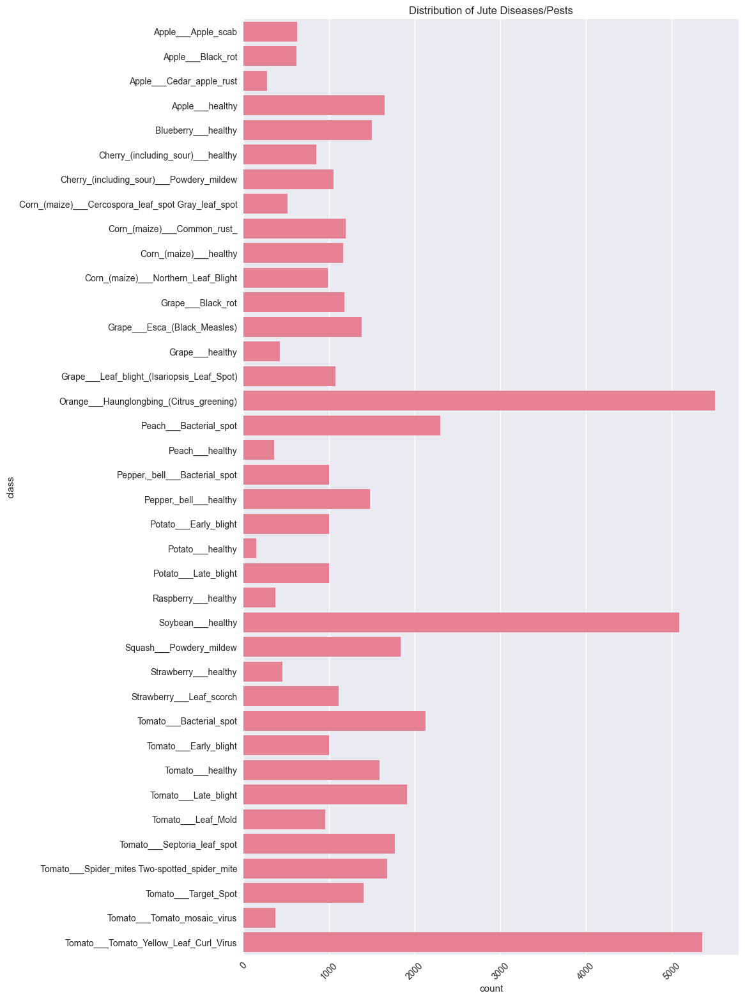

In [ ]:
EDA.get_class_distribution(PLANTVILLAGE_DIR)

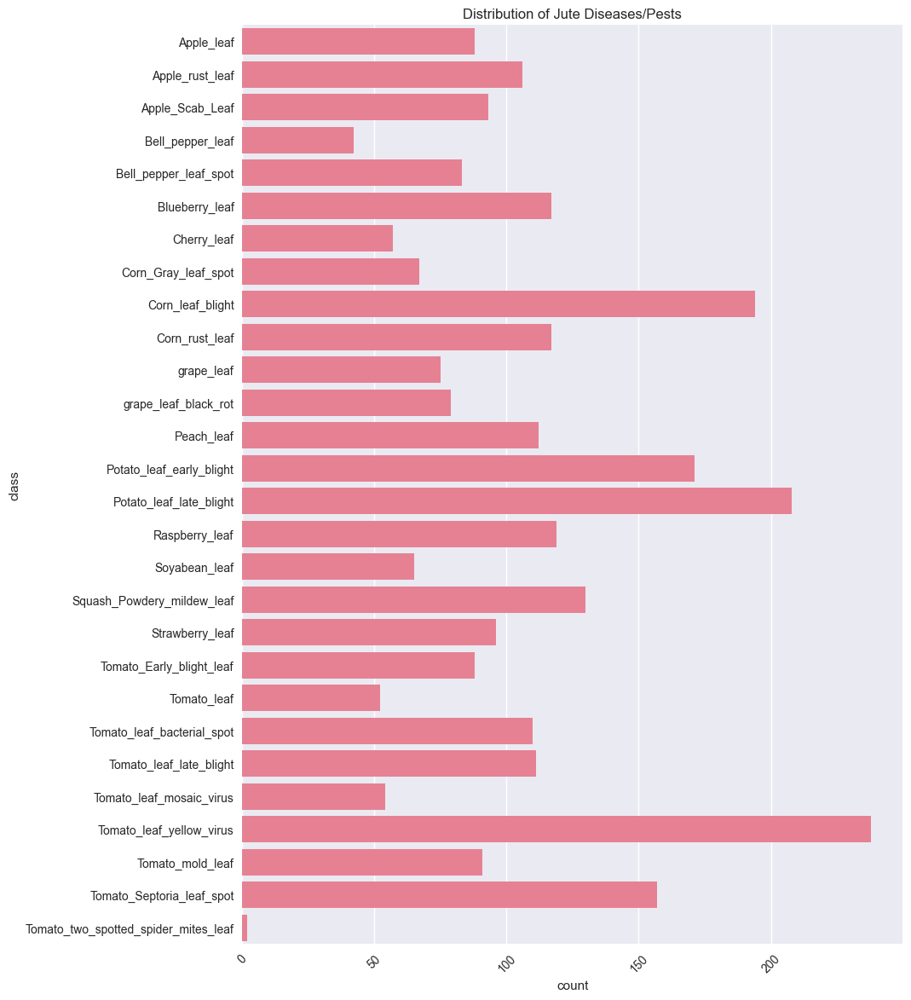

In [ ]:
EDA.get_class_distribution(PLANTDOC_DIR)

### Dataset Description
Next, we will go through the an important characteristic of the images before being used for training, specifically, the image size. This is because it is important to have the image sizes be standardized to uniform shapes to ensure that our model is able to correctly and efficiently process our image data. 

Scanning images...


100%|██████████| 2388/2388 [00:22<00:00, 107.58it/s]



--- Image Size Summary Statistics ---
             width       height
count  2382.000000  2382.000000
mean   2506.892527  1909.249370
std    2151.234274  1386.981204
min     754.000000   565.000000
25%    1024.000000  1024.000000
50%    1024.000000  1024.000000
75%    4624.000000  2600.000000
max    9248.000000  9248.000000

Plot saved as 'image_size_distribution.png'


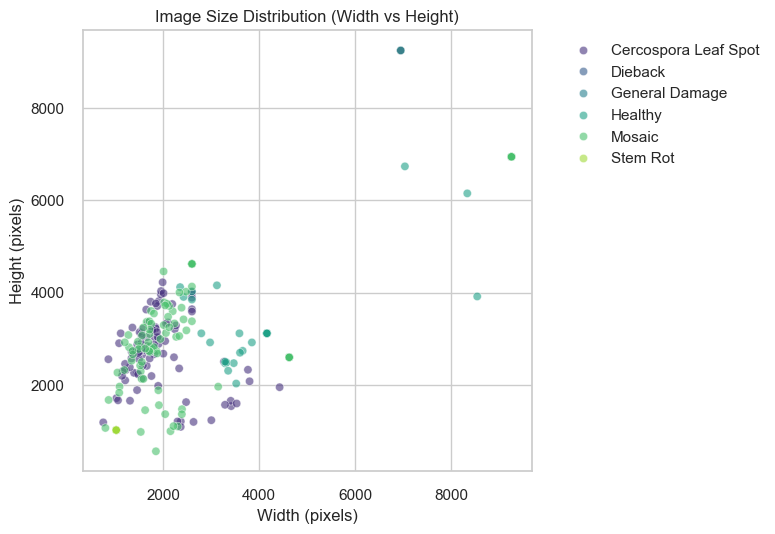

In [ ]:
EDA.get_image_size_description(BY_CLASS_DIR)

The `Image Size Distribution` Figure above indicates that the images that will be used from the`by_class` folder has varying dimensions. This will then be noted for for the preprocessing. 

Scanning images...


100%|██████████| 54343/54343 [00:35<00:00, 1523.81it/s]



--- Image Size Summary Statistics ---
         width   height
count  54305.0  54305.0
mean     256.0    256.0
std        0.0      0.0
min      256.0    256.0
25%      256.0    256.0
50%      256.0    256.0
75%      256.0    256.0
max      256.0    256.0

Plot saved as 'image_size_distribution.png'


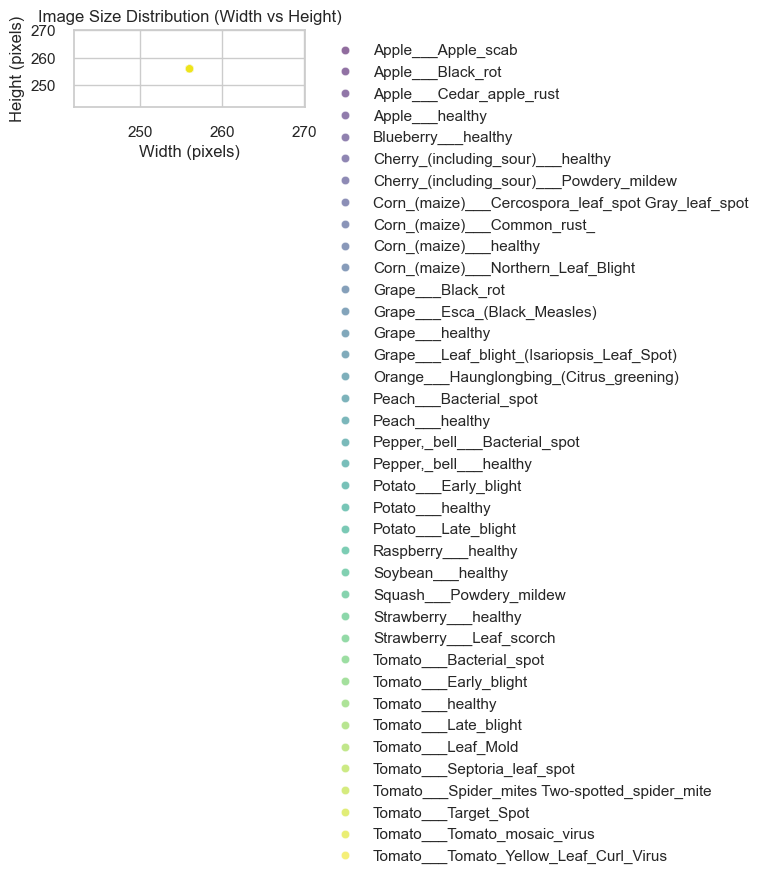

In [ ]:
EDA.get_image_size_description(PLANTVILLAGE_DIR)

Given that the figure for `Plant Village` shows only one dimension, and that the min and max indicate a similar value of `256x256`, it means that the dimensions have already been resized to that standard. 

Scanning images...


100%|██████████| 2950/2950 [00:02<00:00, 1082.93it/s]



--- Image Size Summary Statistics ---
             width       height
count  2922.000000  2922.000000
mean    911.880561   800.503765
std     786.579356   678.954953
min     115.000000    69.000000
25%     400.250000   350.000000
50%     640.000000   560.500000
75%    1155.750000  1024.000000
max    6000.000000  6000.000000

Plot saved as 'image_size_distribution.png'


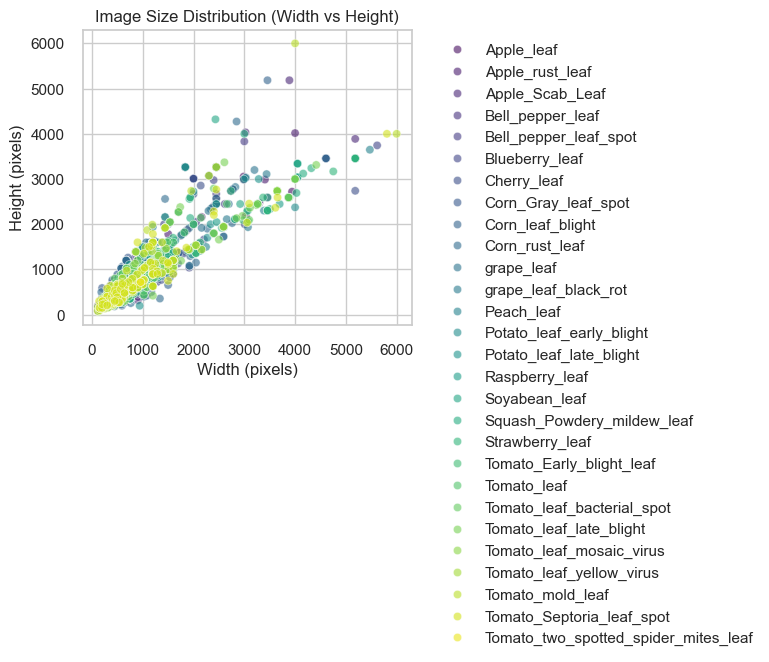

In [ ]:
EDA.get_image_size_description(PLANTDOC_DIR)

The `Image Size Distribution` Figure above indicates that the images that will be used from the`PlantDoc` folder has varying dimensions. This will then be also noted for for the preprocessing. 

Now that we have looked over all the data that we will be using, its dimensions are summarized as follows:
1. by_class: Varying dimensions
2. Plant Village: Uniform dimensions (256x256)
3. Plant Doc: Varying dimensions

### Image Preview
Lastly, we want to preview the images so that we can have an overview of what the diseases look like. This information will allow us to have a better understanding of what features we look for when identifying these diseases. In the context of feature extraction, these may come in handy when defining handcrafted feeatures. 

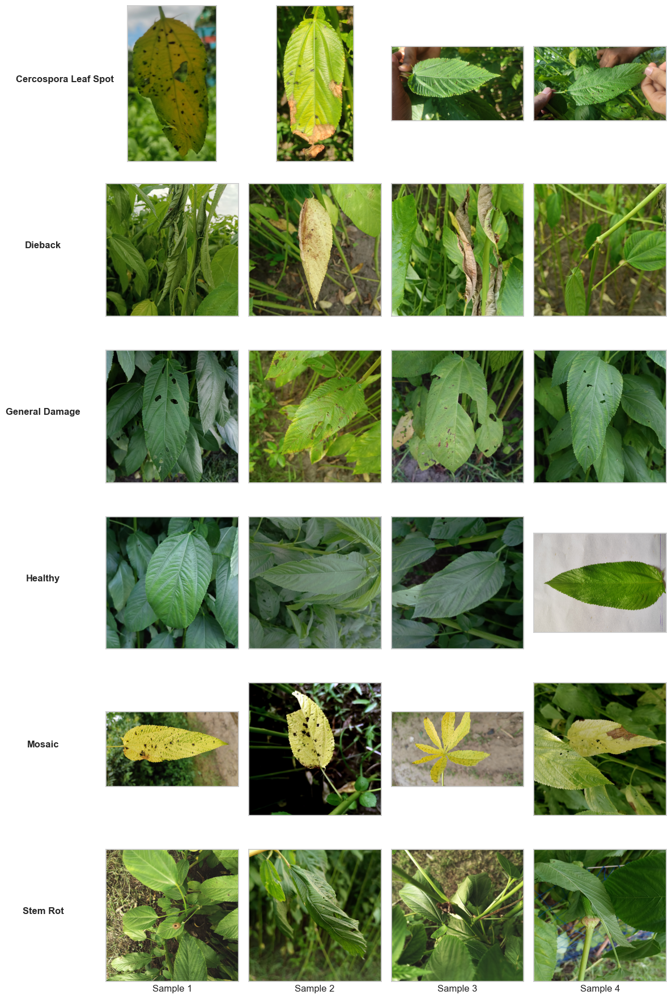

In [ ]:
EDA.preview_class_samples(BY_CLASS_DIR, num_samples=4)

The following are descriptions to these classes:
- **Cercospora Leaf Spot**: A fungal disease that affect jute leaves which is characterized by leaf spots that begins as small, round, brown lesions and often with white/light brown center (Sakar et al., 2016)
- **Dieback**: Characterized by how the apex of the main stem or branch withers and dry up from the tip downwards (Girne American University, 2021). 
- **General Damage**: This classification is characterized by pysical damage that appear on the jute leaves, specifically, holes. 
- **Healthy**: This classification contains jute leaves which were assesseed to be healthy.
- **Mosaic**: Characterized by yellowish flakes on the leaves which expand, eventually leading to wilting of the plants (Begum et al., 2025).
- **Stem Rot**: Characterized by the exposed fibers of the stem and as black lesions are developed (Girne American University, 2021). 

Looking into the sampled images, the afforementioned characteristics may be observed and match the descriptions. We can see that they were taken in the wild wherein the background often includes the ground, surrounding plants, and hands. As non-experts in the jute leaf diseases ourselves, we realize that there are instances wherein it's a bit difficult to correctly identify that classification of the sampled images. For instance, in the sampled `Mosaic` images, we can see that there are holes present. Another observation we noticed is that in the first image of `Cercospora Leaf Spot`, it somewhat resembles a leaf with `Mosaic` symptoms and even `General Damage` (presence of holes). 

For the `PlantDoc` and `PlantVillage`, below are sampled images that we may also view as a means of understanding what kind of diseases will be used for the transfer learning process. 




In [ ]:
EDA.preview_class_samples(PLANTVILLAGE_DIR, num_samples=4)

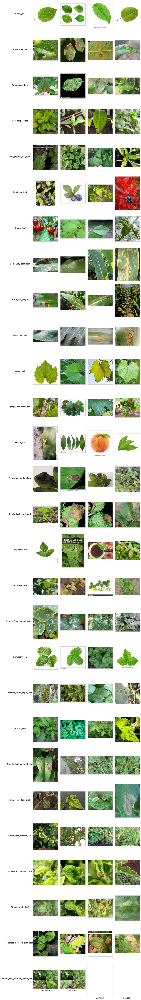

In [ ]:
EDA.preview_class_samples(PLANTDOC_DIR, num_samples=4)

## References:
- Begum, F., Rashid, K., & Fahim, F. H. (2025). Field Screening and Evaluation of the Varietal Performance of Jute and Allied Fiber Crops against Viral and Nemic Disease and Their Impact on Yield. American Journal of Plant Sciences, 16(01), 76–87. https://doi.org/10.4236/ajps.2025.161009
- Girne American University (2021). Diseases of Jute. https://gau.edu.bd/tanbir/wp-content/uploads/sites/170/2021/09/14-Diseases-of-Jute.pdf
- Sarkar, S., & Gawande, S. (2016). Diseases of jute and allied fibre crops and their management Diseases of Jute and allied fibre crops and their management. J. Mycopathol. Res, 54(3), 971–3719. https://imskolkata.org/article1/002-10-16.pdf

‌

‌

‌